<h1 style="text-align:center">Reinforcement Learning</h1> 

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output
import time
import random


In [ ]:
class RandomAgent:
    def __init__(self, action_space=["up", "down", "left", "right"]):
        self.action_space = action_space

    def act(self):
        """Choose a random action from available actions."""
        return random.choice(self.action_space)

    def observe(self, position, reward, breeze, smell, end_episode, info):
        """Random agent receives info but does not learn from it."""
        pass
    
    def reset(self):
        """Needed for compatibility with learning agents (end of episode)."""
        pass
    
    def reset_episode(self):
        """Needed for compatibility with learning agents (start of episode)."""
        pass

class VanillaGridWorld:
    def __init__(self, size=5, agent=None):
        self.size = size
        self.agent = agent
        self.agent_position = [0, 0] 
        self.goal = [size-1, size-1] 
        self.timestep = 0
        self.action_space = ["up", "down", "left", "right"]
        self.visualize = True  

    def move(self, position, action):
        x, y = position
        if action == "up": x = max(0, x-1)
        if action == "down": x = min(self.size-1, x+1)
        if action == "left": y = max(0, y-1)
        if action == "right": y = min(self.size-1, y+1)
        return [x, y]

    def step(self, write=True):
        self.timestep += 1
        
        state_before = tuple(self.agent_position)
        
        action = self.agent.act()
        
        self.agent_position = self.move(self.agent_position, action)
        
        done = (self.agent_position == self.goal)
        reward = 10 if done else -1
        
        info = {
            "action": action, 
            "prev_state": state_before
        }

        self.agent.observe(tuple(self.agent_position), reward, 0, 0, done, info)

        if write and self.visualize:
            self.build_frame()

        return self.agent_position, reward, done

    def run_episode(self, max_steps=1000, write=True):
        self.reset()
        
        if hasattr(self.agent, "reset_episode"):
            self.agent.reset_episode()
        elif hasattr(self.agent, "reset"):
            self.agent.reset()

        for _ in range(max_steps):
            _, _, done = self.step(write=write)
            if done:
                break
        
        if hasattr(self.agent, "reset"):
            self.agent.reset()

        return self.timestep

    def reset(self):
        self.agent_position = [0,0]
        self.timestep = 0

    def display_greedy_episode(self, max_steps=100):
        """Forces agent to act greedily (no exploration) and visualizes."""
        old_eps = getattr(self.agent, 'epsilon', getattr(self.agent, 'EPSILON', None))
        
        if hasattr(self.agent, 'epsilon'): self.agent.epsilon = 0
        if hasattr(self.agent, 'EPSILON'): self.agent.EPSILON = 0

        print("Displaying Greedy Episode...")
        self.visualize = True
        steps = self.run_episode(max_steps=max_steps, write=True)

        if old_eps is not None:
            if hasattr(self.agent, 'epsilon'): self.agent.epsilon = old_eps
            if hasattr(self.agent, 'EPSILON'): self.agent.EPSILON = old_eps
        
        print(f"Greedy episode finished in {steps} steps.")

    def build_frame(self):
        grid = np.ones((self.size, self.size, 3)) * 0.9
        grid[self.goal[0], self.goal[1]] = [0,1,0]    
        grid[self.agent_position[0], self.agent_position[1]] = [0,0,1] 

        clear_output(wait=True)
        plt.figure(figsize=(5,5))
        plt.imshow(grid)
        plt.axis('off')
        plt.title(f"Vanilla Grid - Step {self.timestep}")
        plt.show()
        time.sleep(0.1) 


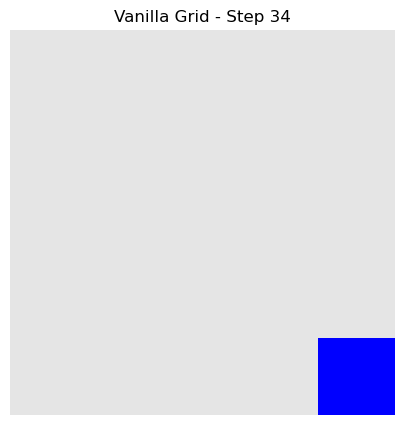

34

In [ ]:
agent1 = RandomAgent(action_space=["up","down","left","right"])
vanilla_env = VanillaGridWorld(size=5, agent=agent1)

vanilla_env.visualize = True 
vanilla_env.run_episode(max_steps=100, write=True)

In [ ]:
import inspect
print(inspect.getsource(vanilla_env.move))
print(inspect.getsource(vanilla_env.reset))
print(inspect.getsource(vanilla_env.display_greedy_episode))

    def move(self, position, action):
        x, y = position
        if action == "up": x = max(0, x-1)
        if action == "down": x = min(self.size-1, x+1)
        if action == "left": y = max(0, y-1)
        if action == "right": y = min(self.size-1, y+1)
        return [x, y]

    def reset(self):
        self.agent_position = [0,0]
        self.timestep = 0

    def display_greedy_episode(self, max_steps=100):
        """Forces agent to act greedily (no exploration) and visualizes."""
        # Capture current epsilon/EPSILON
        old_eps = getattr(self.agent, 'epsilon', getattr(self.agent, 'EPSILON', None))

        # Disable exploration
        if hasattr(self.agent, 'epsilon'): self.agent.epsilon = 0
        if hasattr(self.agent, 'EPSILON'): self.agent.EPSILON = 0

        print("Displaying Greedy Episode...")
        self.visualize = True
        steps = self.run_episode(max_steps=max_steps, write=True)

        # Restore exploration
        if old_eps is not None:
     

In [ ]:
print(inspect.getsource(agent1.observe))
print(inspect.getsource(agent1.act))

    def observe(self, position, reward, breeze, smell, end_episode, info):
        """Random agent receives info but does not learn from it."""
        pass

    def act(self):
        """Choose a random action from available actions."""
        return random.choice(self.action_space)



In [ ]:
class RandomAgent:
    def act(self):
        return random.choice(['up','down','left','right'])
    def observe(self, position, reward, breeze, smell, end_episode, info):
        pass  # can be extended to log observations

class WumpusEnvVisual:
    def __init__(self, size=5, agent=None):
        self.size = size
        self.agent = agent or RandomAgent()
        self.timestep = 0
        self.frames = []
        self.reset()

    def reset(self):
        self.agent_position = (0,0)
        self.wumpus_position = (self.size-1, self.size-1)
        self.goal_position = (self.size-1, 0)
        self.timestep = 0
        self.frames = []

    def run_episode(self, max_length=100, write=True, delay=0.2):
        self.reset()
        self.build_frame()
        for _ in range(max_length):
            agent_position, reward, breeze, smell, end_episode, info = self.step(write=write, max_length=max_length)
            if write:
                self.render()  # visualize live
                time.sleep(delay)
            if end_episode:
                print(f"Episode ended: {info}, reward={reward}")
                break
        if write:
            self.build_frame()
        return agent_position, reward, breeze, smell, end_episode, info

    def step(self, write=True, max_length=100):
        self.timestep += 1

        action = self.agent.act()
        self.agent_position = self.move(self.agent_position, action)

        self.move_wumpus()

        self.agent_position = self.wind_action(self.agent_position)

        info, end_episode = self.end_episode(max_length=max_length)

        reward = self.reward(info)

        smell = self.smell()
        breeze = self.breeze()

        self.agent.observe(self.agent_position, reward, breeze, smell, end_episode, info)

        if write:
            self.build_frame()

        return self.agent_position, reward, breeze, smell, end_episode, info

    def move(self, position, action):
        x, y = position
        if action == 'up': x = max(0, x-1)
        if action == 'down': x = min(self.size-1, x+1)
        if action == 'left': y = max(0, y-1)
        if action == 'right': y = min(self.size-1, y+1)
        return (x, y)

    def move_wumpus(self):
        x, y = self.wumpus_position
        moves = []
        if x > 0: moves.append('up')
        if x < self.size-1: moves.append('down')
        if y > 0: moves.append('left')
        if y < self.size-1: moves.append('right')
        if moves:
            action = random.choice(moves)
            if action == 'up': x -= 1
            if action == 'down': x += 1
            if action == 'left': y -= 1
            if action == 'right': y += 1
            self.wumpus_position = (x, y)

    def wind_action(self, position):
        if random.random() < 0.1:
            return self.move(position, random.choice(['up','down','left','right']))
        return position

    def end_episode(self, max_length=100):
        if self.agent_position == self.wumpus_position:
            return "Eaten by Wumpus", True
        if self.agent_position == self.goal_position:
            return "Reached Goal", True
        if self.timestep >= max_length:
            return "Max steps reached", True
        return "Continue", False

    def reward(self, info):
        if info == "Reached Goal": return 100
        if info == "Eaten by Wumpus": return -100
        return -1

    def smell(self):
        ax, ay = self.agent_position
        wx, wy = self.wumpus_position
        return abs(ax-wx) + abs(ay-wy) == 1

    def breeze(self):
        return False

    def build_frame(self):
        self.frames.append((self.agent_position, self.wumpus_position))

    def create_video(self):
        pass

    def render(self):
        grid = np.zeros((self.size, self.size, 3))
        ax, ay = self.agent_position
        grid[ax, ay] = [0,0,1]
        wx, wy = self.wumpus_position
        grid[wx, wy] = [1,0,0]
        gx, gy = self.goal_position
        grid[gx, gy] = [0,1,0]
        clear_output(wait=True)
        plt.imshow(grid, origin='upper')
        plt.axis('off')
        plt.title(f"Timestep {self.timestep}")
        plt.show()

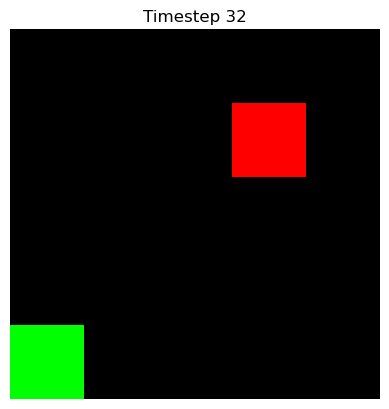

Episode ended: Eaten by Wumpus, reward=-100


((1, 3), -100, False, False, True, 'Eaten by Wumpus')

In [ ]:
env = WumpusEnvVisual(agent=RandomAgent())
env.run_episode(max_length=200, write=True, delay=0.1)

In [ ]:
class RandomAgent:
    def __init__(self, action_space=["up", "down", "left", "right"]):
        self.action_space = action_space

    def act(self):
        """Pick a random move regardless of state."""
        return random.choice(self.action_space)

    def observe(self, state, reward, breeze, smell, done, info):
        """Ignore feedback as this agent doesn't learn."""
        pass

    def reset(self):
        """Placeholder for compatibility with learning agents."""
        pass

class WindyGridWorld:
    def __init__(self, size=5, agent=None):
        self.size = size
        self.state = [0, 0]
        self.goal = [size-1, size-1]
        self.agent = agent
        self.action_space = ["up", "down", "left", "right"]
        self.wind_cells = [(1, 2), (2, 2), (3, 1)]
        self.write = True

    def move(self, position, action):
        x, y = position
        if action == "up":    x = max(0, x-1)
        if action == "down":  x = min(self.size-1, x+1)
        if action == "left":  y = max(0, y-1)
        if action == "right": y = min(self.size-1, y+1)
        return [x, y]

    def step(self, write=True):
        state_before = tuple(self.state)
        
        action = self.agent.act()
        
        self.state = self.move(self.state, action)
        
        if tuple(self.state) in self.wind_cells:
            wind_action = random.choice(self.action_space)
            self.state = self.move(self.state, wind_action)

        done = (self.state == self.goal)
        reward = 0 if done else -1 
        
        info = {"prev_state": state_before, "action": action}
        self.agent.observe(tuple(self.state), reward, None, None, done, info)

        return self.state, reward, done

    def run_episode(self, delay=0.1, max_steps=100, write=True):
        self.state = [0, 0]
        steps = 0
        
        if hasattr(self.agent, "reset_episode"):
            self.agent.reset_episode()

        while steps < max_steps:
            steps += 1
            _, _, done = self.step(write=write)

            if write:
                self.render()
                time.sleep(delay)

            if done:
                print(f"Goal reached in {steps} steps!")
                break
        
        self.agent.reset() 
        return steps

    def display_greedy_episode(self, max_steps=100, delay=0.2):
        """Forces agent to act greedily (epsilon=0) and visualizes."""
        old_eps = getattr(self.agent, 'epsilon', getattr(self.agent, 'EPSILON', None))
        
        if hasattr(self.agent, 'epsilon'): self.agent.epsilon = 0
        if hasattr(self.agent, 'EPSILON'): self.agent.EPSILON = 0

        print("--- RUNNING GREEDY EPISODE ---")
        steps = self.run_episode(delay=delay, max_steps=max_steps, write=True)
        
        if old_eps is not None:
            if hasattr(self.agent, 'epsilon'): self.agent.epsilon = old_eps
            if hasattr(self.agent, 'EPSILON'): self.agent.EPSILON = old_eps
        return steps

    def render(self):
        grid = np.ones((self.size, self.size, 3)) * 0.9 
        for (i, j) in self.wind_cells:
            grid[i, j] = [0.6, 0.6, 0.6]
        grid[self.state[0], self.state[1]] = [0, 0, 1]
        grid[self.goal[0], self.goal[1]] = [0, 1, 0]
        
        clear_output(wait=True)
        plt.imshow(grid, origin='upper')
        plt.axis('off')
        plt.title(f"Windy World - Position: {self.state}")
        plt.show()

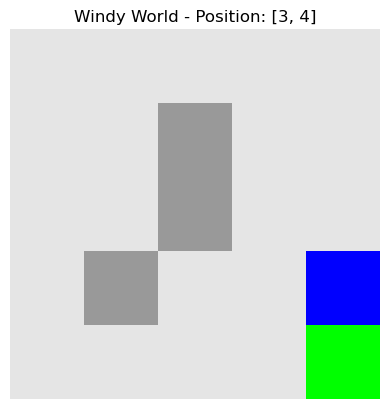

50

In [ ]:
Agent1 = RandomAgent()
env = WindyGridWorld(size=5, agent=Agent1)
env.run_episode(delay=0.1, max_steps=50, write=True)

In [ ]:
class RandomAgent:
    def __init__(self, action_space=["up", "down", "left", "right"]):
        self.action_space = action_space

    def act(self):
        return random.choice(self.action_space)

    def observe(self, state, reward, breeze, smell, done, info):
        pass 

    def reset(self):
        pass

class CliffGridWorld:
    def __init__(self, width=12, height=4, agent=None):
        self.width = width
        self.height = height
        self.start = [height-1, 0]
        self.state = list(self.start)
        self.goal = [height-1, width-1]
        self.agent = agent
        self.action_space = ["up", "down", "left", "right"]
        self.cliff = [[height-1, y] for y in range(1, width-1)]
        self.visualize = True

    def move(self, position, action):
        x, y = position
        if action == "up":    x = max(0, x-1)
        if action == "down":  x = min(self.height-1, x+1)
        if action == "left":  y = max(0, y-1)
        if action == "right": y = min(self.width-1, y+1)
        return [x, y]

    def step(self, write=True):
        state_before = tuple(self.state)
        
        if hasattr(self.agent, 'act'):
            action = self.agent.act()
        else:
            action = self.agent.choose_action(self.state, self.goal, self.cliff)

        self.state = self.move(self.state, action)
        
        done = (self.state == self.goal)
        reward = -1 
        
        if list(self.state) in self.cliff:
            reward = -100
            self.state = list(self.start) 

        if hasattr(self.agent, 'observe'):
            info = {"prev_state": state_before, "action": action}
            self.agent.observe(tuple(self.state), reward, 0, 0, done, info)

        return self.state, reward, done

    def run_episode(self, max_steps=100, write=True, delay=0.01):
        self.state = list(self.start)
        if hasattr(self.agent, 'reset'): 
            self.agent.reset()

        steps = 0
        while steps < max_steps:
            steps += 1
            _, _, done = self.step(write=write)
            
            if write and self.visualize:
                self.render(steps)
                time.sleep(delay)
            
            if done:
                if write: print(f"Goal reached in {steps} steps!")
                break
        else:
            if write: print(f"Stopped after {max_steps} steps without goal.")
        
        if hasattr(self.agent, 'learn'): 
            self.agent.learn()
            
        return steps

    def render(self, step_num):
        grid = np.ones((self.height, self.width, 3)) * 0.9
        for (x, y) in self.cliff: 
            grid[x, y] = [0, 0, 0]            
        grid[self.start[0], self.start[1]] = [1, 0.4, 0.7] 
        grid[self.goal[0], self.goal[1]] = [0, 1, 0]     
        grid[self.state[0], self.state[1]] = [0, 0, 1]   
        
        clear_output(wait=True)
        plt.figure(figsize=(10, 3))
        plt.imshow(grid)
        plt.title(f"Step: {step_num}")
        plt.axis('off')
        plt.show()

    def display_greedy_episode(self, max_length=100):
        old_eps = getattr(self.agent, 'epsilon', getattr(self.agent, 'EPSILON', None))
        
        if hasattr(self.agent, 'epsilon'): self.agent.epsilon = 0
        if hasattr(self.agent, 'EPSILON'): self.agent.EPSILON = 0

        self.visualize = True
        steps = self.run_episode(max_steps=max_length, write=True)

        if old_eps is not None:
            if hasattr(self.agent, 'epsilon'): self.agent.epsilon = old_eps
            if hasattr(self.agent, 'EPSILON'): self.agent.EPSILON = old_eps
        
        return steps

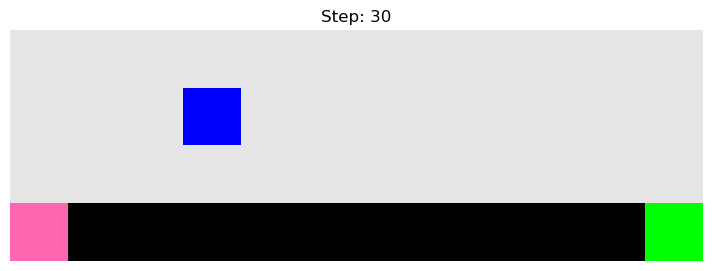

Stopped after 30 steps without goal.


30

In [ ]:
agent_rand = RandomAgent()
env_rand = CliffGridWorld(agent=agent_rand)
env_rand.run_episode(max_steps=30, write=True, delay=0.1)

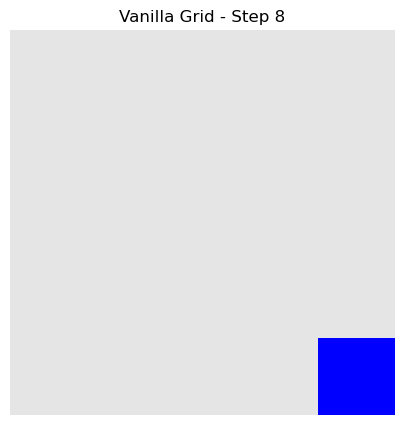

8

In [ ]:
class DownRightAgent:
    def __init__(self, action_space=["down", "right"]):
        self.action_space = action_space

    def act(self):
        """Choose a random action from available actions."""
        return random.choice(self.action_space)

    def observe(self, position, reward, breeze, smell, end_episode, info):
        """Random agent receives info but does not learn from it."""
        pass

    def reset(self):
        """Needed for compatibility with learning agents (end of episode)."""
        pass

    def reset_episode(self):
        """Needed for compatibility with learning agents (start of episode)."""
        pass

agent11 = DownRightAgent(action_space=["down","right"])
vanilla_env = VanillaGridWorld(size=5, agent=agent11)
vanilla_env.visualize = True  # Set False to disable visualization
vanilla_env.run_episode(max_steps=100, write=True)

## Part 2: Algorithms

In [28]:
class Agent:
    def __init__(self, *args, **kwargs):
        pass 

In [ ]:
import numpy as np
class MonteCarloAgent(Agent):
    def __init__(self, prefix='MC_GLIE', grid_size=(5, 5), EPSILON=1., GAMMA=0.8):
        
        self.prefix = prefix 
        
        self.set_of_actions = ['up', 'down', 'left', 'right']
        
        self.EPSILON = EPSILON
        
        self.GAMMA = GAMMA
        
        self.Q_function = np.random.uniform(size=(grid_size[0], grid_size[1], len(self.set_of_actions)))
        
        self.N = np.zeros(shape=(grid_size[0], grid_size[1], len(self.set_of_actions)))
        
        self.position = (0, 0)
        
        self.actions = []
        self.states = []
        self.rewards = []
        
        self.episode = 0
        
        pass
    
    def act(self):
        self.states.append(self.position)
        
        if np.random.uniform() < self.EPSILON:
            action = np.random.choice(self.set_of_actions)
        else : 
            action = self.set_of_actions[np.argmax(self.Q_function[self.position[0], self.position[1]])]
        
        self.actions.append(action)
        
        return action
    
    def observe(self, agent_position, reward, breeze, smell, end_episode, info): 
        self.rewards.append(reward)

        self.position = agent_position
        
        pass

    def reset(self):
        GAMMAtime = 0
        for time in reversed(range(len(self.states))):
            statetime = self.states[time]
            actiontime = self.actions[time]
            rewardtime = self.rewards[time]
            a_idx = self.set_of_actions.index(actiontime)
            GAMMAtime = rewardtime + self.GAMMA * GAMMAtime
            self.N[statetime[0], statetime[1], a_idx] += 1
            self.Q_function[statetime[0], statetime[1], a_idx] += (1 / self.N[statetime[0], statetime[1], a_idx]) * (GAMMAtime - self.Q_function[statetime[0], statetime[1], a_idx])

        self.episode += 1
        self.EPSILON = 1 / (1 + 0.01 * self.episode)
        self.states, self.actions, self.rewards = [], [], []
        self.position = (0, 0)

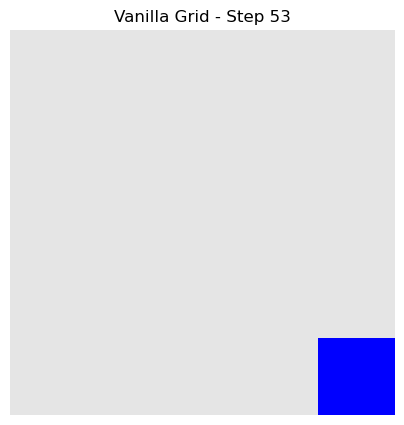

53

In [ ]:
mc_agent = MonteCarloAgent(grid_size=(5, 5))
mc_env = VanillaGridWorld(size=5, agent=mc_agent)
mc_env.run_episode(max_steps=100, write=True)

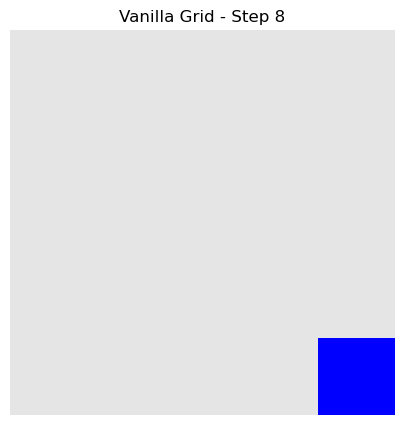

Greedy episode finished in 8 steps.


In [ ]:
for _ in range(5000):
    mc_env.run_episode(max_steps=100, write=False)
mc_env.display_greedy_episode(max_steps=20)

In [ ]:
print(mc_agent.EPSILON)

0.009899029895070284


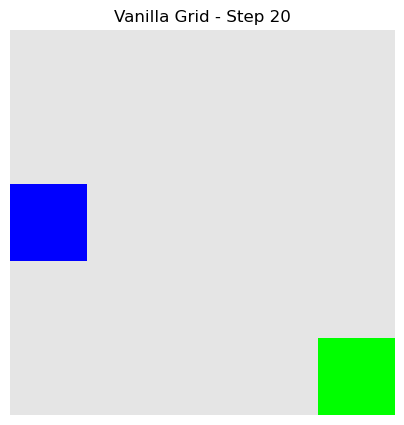

Greedy episode finished in 20 steps.


In [ ]:
mc_agent2 = MonteCarloAgent(grid_size=(5, 5), EPSILON=0)
mc_env2 = VanillaGridWorld(size=5, agent=mc_agent2)
mc_env2.run_episode(max_steps=100, write=True)
mc_env2.display_greedy_episode(max_steps=20)

In [ ]:
mc_agent3 = MonteCarloAgent(prefix='windy-MC', grid_size=(7, 10))
mc_env3 = WindyGridWorld(size=7, agent=mc_agent3)

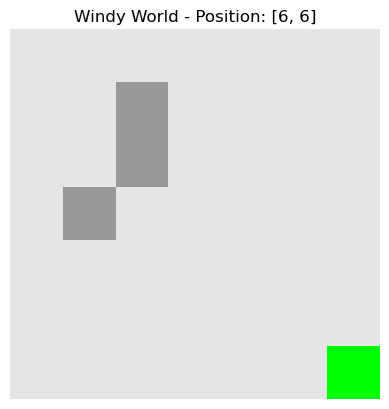

Goal reached in 13 steps!


13

In [ ]:
for _ in range(5000):
    mc_env3.run_episode(max_steps=100, write=False)
mc_env3.display_greedy_episode(max_steps=50)

In [ ]:
# Monte Carlo focus on explotation reward mechanism. It's a straightforward strategy that seems not able to overcome stochastic environnements nor hills.

In [43]:
class Agent:
    def __init__(self, *args, **kwargs):
        pass

In [ ]:
class SarsaAgent(Agent):
    def __init__(self, prefix='SARSA', grid_size=(7,10), starting_position=(3, 0), gold_position = (3,7), epsilon=0.5, gamma=.8, holes_positions=[]):

        self.prefix = prefix

        self.set_of_actions = ['up', 'down', 'right', 'left']
        self.number_of_actions = len(self.set_of_actions)

        self.starting_position = starting_position

        self.Q_function = np.random.uniform(size=(grid_size[0], grid_size[1], self.number_of_actions))

        self.Q_function[gold_position[0], gold_position[1]] = 0
        for hole in holes_positions:
            self.Q_function[hole[0], hole[1]] = 0

        self.ALPHA = 1
        self.GAMMA = gamma
        self.EPSILON = epsilon

        self.current_action = None
        self.previous_action = None
        self.current_reward = None
        self.previous_reward = None
        self.current_position = self.starting_position
        self.previous_position = None
        
        self.step_number = 0

        pass

    def act(self):
        
        self.previous_action = self.current_action

        if np.random.uniform() < self.EPSILON:
            action = np.random.choice(self.set_of_actions)
        else:
            action_index = np.argmax(self.Q_function[self.current_position[0], self.current_position[1]])
            action = self.set_of_actions[action_index]
    
        self.current_action = action
        
        self.step_number+=1
        
        self.ALPHA = 1/self.step_number
      
        return action

     
    def observe(self, agent_position, reward, breeze, smell, end_episode, info):
        s = self.current_position
        a_idx = self.set_of_actions.index(self.current_action)
        s_prime = agent_position

        if not end_episode:
            if np.random.uniform() < self.EPSILON:
                a_prime = np.random.choice(self.set_of_actions)
            else:
                a_prime = self.set_of_actions[np.argmax(self.Q_function[s_prime[0], s_prime[1]])]
            a_prime_idx = self.set_of_actions.index(a_prime)
            td_target = reward + self.GAMMA * self.Q_function[s_prime[0], s_prime[1], a_prime_idx]
        else:
            td_target = reward

        self.Q_function[s[0], s[1], a_idx] += self.ALPHA * (td_target - self.Q_function[s[0], s[1], a_idx])
        self.current_position = agent_position

    def reset(self):
        self.previous_action = None
        self.previous_reward = None
        self.previous_position = None
        self.current_action = None
        self.current_reward = None
        self.current_position = self.starting_position
        self.step_number = 1
        pass

In [ ]:
sarsa_agent = SarsaAgent(grid_size=(10,10), starting_position=(0,0), gold_position=(9,9))
sarsa_env = VanillaGridWorld(size=10, agent=sarsa_agent)
sarsa_env.goal = [9, 9]

In [ ]:
for _ in range(1000):
    sarsa_env.run_episode(max_steps=200, write=False)

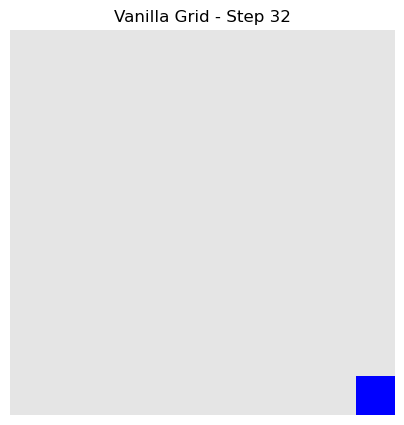

Greedy episode finished in 32 steps.


In [ ]:
sarsa_env.display_greedy_episode(max_steps=50)

In [ ]:
# SARSA is consistent but decreases greedy behaviour. It seems to be less efficient in a such basic environment than Monte Carlo.

In [53]:
class Agent:
    def __init__(self, *args, **kwargs):
        pass

In [ ]:
class QAgent(Agent):
    def __init__(self, prefix='QAgent', grid_size=(7,10), starting_position=(3, 0), gold_position = (3,7), epsilon=0.5, gamma=.8, holes_positions=[]):

        self.prefix = prefix

        self.set_of_actions = ['up', 'down', 'right', 'left']
        self.number_of_actions = len(self.set_of_actions)

        self.starting_position = starting_position

        self.Q_function = np.random.uniform(size=(grid_size[0], grid_size[1], self.number_of_actions))
        self.Q_function[gold_position[0], gold_position[1]] = 0
        for hole in holes_positions:
            self.Q_function[hole[0], hole[1]] = 0

        self.ALPHA = 1
        self.GAMMA = gamma
        self.EPSILON = epsilon

        self.current_action = None
        self.previous_action = None
        self.current_reward = None
        self.previous_reward = None
        self.current_position = self.starting_position
        self.previous_position = None
        self.step_number = 0

        pass

    def act(self):
        self.previous_action = self.current_action 
        if np.random.uniform() < self.EPSILON:
            action = np.random.choice(self.set_of_actions)
        else:
            action_index = np.argmax(self.Q_function[self.current_position[0], self.current_position[1]])
            action = self.set_of_actions[action_index]
        self.current_action = action
        self.step_number += 1
        self.ALPHA = 1/self.step_number
      
        return action

    def observe(self, agent_position, reward, breeze, smell, end_episode, info):
        s = self.current_position
        a_idx = self.set_of_actions.index(self.current_action)
        s_prime = agent_position

        if not end_episode:
            td_target = reward + self.GAMMA * np.max(self.Q_function[s_prime[0], s_prime[1]])
        else:
            td_target = reward

        self.Q_function[s[0], s[1], a_idx] += self.ALPHA * (td_target - self.Q_function[s[0], s[1], a_idx])
        self.current_position = agent_position

    def reset(self):
        self.previous_action = None
        self.previous_reward = None
        self.previous_position = None
        self.current_action = None
        self.current_reward = None
        self.current_position = self.starting_position
        self.step_number = 1
        pass

In [ ]:
q_agent = QAgent(grid_size=(10,10), starting_position=(0,0), gold_position=(9,9))
q_env = VanillaGridWorld(size=10, agent=q_agent)
q_env.goal = [9, 9]

In [ ]:
for _ in range(1000):
    q_env.run_episode(max_steps=200, write=False)

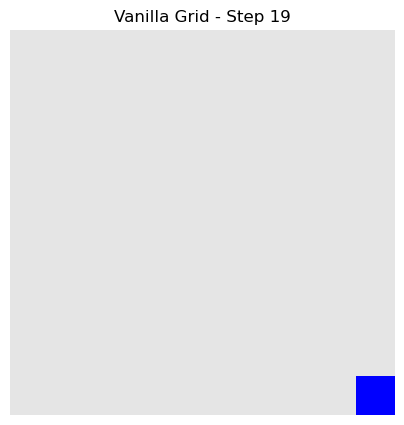

Greedy episode finished in 19 steps.


In [ ]:
q_env.display_greedy_episode(max_steps=50)

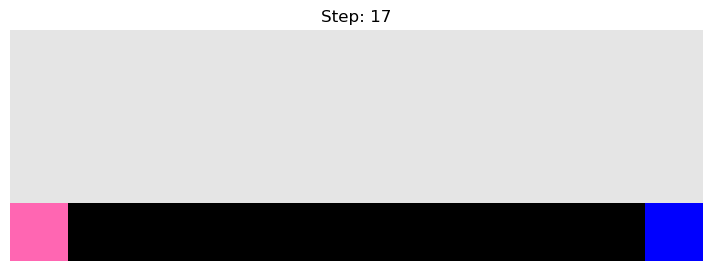

Goal reached in 17 steps!


17

In [ ]:
cliff_sarsa = SarsaAgent(grid_size=(4,12), starting_position=(3,0), gold_position=(3,11), holes_positions=[(3,i) for i in range(1,11)], epsilon=0.1)
cliff_env_sarsa = CliffGridWorld(width=12, height=4, agent=cliff_sarsa)
for _ in range(5000):
    cliff_env_sarsa.run_episode(max_steps=100, write=False)
cliff_env_sarsa.display_greedy_episode()

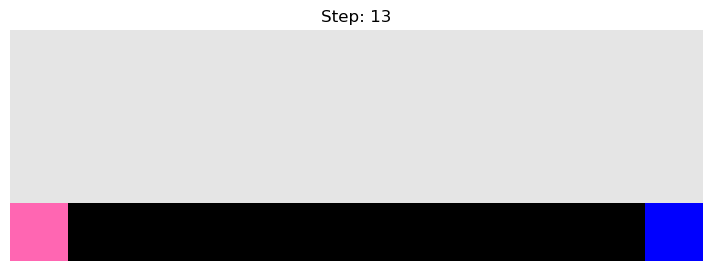

Goal reached in 13 steps!


13

In [ ]:
cliff_q = QAgent(grid_size=(4,12), starting_position=(3,0), gold_position=(3,11), holes_positions=[(3,i) for i in range(1,11)], epsilon=0.1)
cliff_env_q = CliffGridWorld(width=12, height=4, agent=cliff_q)
for _ in range(5000):
    cliff_env_q.run_episode(max_steps=100, write=False)
cliff_env_q.display_greedy_episode()

In [ ]:
# SARSA learnt safer paths while Q-learning learnt an optimal path no matter the risk.
